<a href="https://colab.research.google.com/github/Alejandro120325/Practica_03_El_Perceptron/blob/main/Practica_03_El_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 03: El Perceptrón
**Asignatura:** Inteligencia Artificial  
**Nombre:** Jairo Alejandro Ojeda Herrera

## Fase 1. Exploración del Dataset
### Actividad 1.a - Inspección inicial
**Preguntas guía:**
* **¿Qué representa cada fila de X?** Representa un punto o instancia con sus dos coordenadas $(X_1, X_2)$.
* **¿Qué representa cada valor de y?** Representa la clase real de ese punto ($-1$ o $1$).
* **¿Por qué es clasificación binaria?** Porque solo existen dos clases posibles ($-1$ y $1$).

In [1]:
import random
import matplotlib.pyplot as plt

random.seed(42)

X = [
    [1, 7], [1, 3], [3, 4], [4, 6], [4, 2],
    [6, 6], [6, 2], [6, 0], [7, 4], [9, 3],
    [9, 1], [11, 1], [12, 3], [16, 2],
    [4, 8], [6, 8], [8, 9], [9, 7], [10, 11],
    [12, 9], [12, 6], [14, 7], [16, 4]
]

y = [
    -1, -1, -1, -1, -1,
    -1, -1, -1, -1, -1,
    -1, -1, -1, -1,
    1, 1, 1, 1, 1,
    1, 1, 1, 1
]

total = len(X)
variables = len(X[0])
clase_neg = 0
clase_pos = 0
clases = []

for etiqueta in y:
    if etiqueta not in clases:
        clases.append(etiqueta)
    if etiqueta == -1:
        clase_neg = clase_neg + 1
    else:
        clase_pos = clase_pos + 1

print("Total instancias:", total)
print("Variables:", variables)
print("Clases:", len(clases))
print("Clase -1:", clase_neg)
print("Clase +1:", clase_pos)

Total instancias: 23
Variables: 2
Clases: 2
Clase -1: 14
Clase +1: 9


### Actividad 1.b - Separación visual
**Pregunta guía:**
* **¿Se pueden separar las dos clases con una sola recta?** Sí, porque las cruces rojas ($+1$) están arriba a la derecha y los círculos azules ($-1$) abajo a la izquierda sin mezclarse.

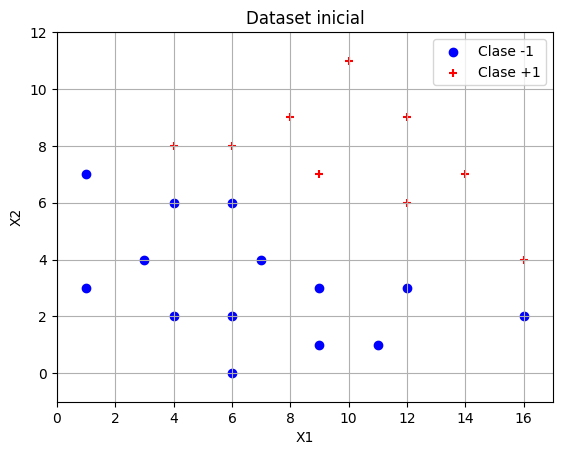

In [2]:
def graficar_puntos(X, y):
    x1_neg, x2_neg = [], []
    x1_pos, x2_pos = [], []

    for i in range(len(X)):
        if y[i] == -1:
            x1_neg.append(X[i][0])
            x2_neg.append(X[i][1])
        else:
            x1_pos.append(X[i][0])
            x2_pos.append(X[i][1])

    plt.scatter(x1_neg, x2_neg, color="blue", marker="o", label="Clase -1")
    plt.scatter(x1_pos, x2_pos, color="red", marker="+", label="Clase +1")
    plt.title("Dataset inicial")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.xlim(0, 17)
    plt.ylim(-1, 12)
    plt.legend()
    plt.grid(True)
    plt.show()

graficar_puntos(X, y)

## Fase 2. Fundamento del Perceptrón
### Actividades 2.a, 2.b y 2.c
**Preguntas guía:**
* **2.a ¿Por qué hay tres pesos y qué hace el bias?** Porque incluye $w_0$ (bias) más $w_1$ y $w_2$. El bias mueve la recta fuera del origen $(0,0)$.
* **2.b ¿Por qué se usa $-1$ y $1$ en lugar de $0$ y $1$?** Porque hace simétrico el ajuste de pesos ($+2$ o $-2$ al fallar) respecto al cero.
* **2.c ¿Diferencia entre $z$ y la salida final? ¿Por qué no basta $z$?** $z$ es un número continuo y la salida es la clase discreta ($-1$ o $1$). Se necesita la clase discreta para compararla con $y$.

In [3]:
def initialize_weights():
    w0 = random.uniform(-0.5, 0.5)
    w1 = random.uniform(-0.5, 0.5)
    w2 = random.uniform(-0.5, 0.5)
    return [w0, w1, w2]

def activation(z):
    if z >= 0:
        return 1
    else:
        return -1

def perceptron_compute(x, w):
    z = w[0] + w[1] * x[0] + w[2] * x[1]
    return activation(z)

w_prueba = initialize_weights()
print("Pesos:", w_prueba)

for i in [0, 8, 18]:
    print(X[i], "Real:", y[i], "Pred:", perceptron_compute(X[i], w_prueba))

Pesos: [0.13942679845788375, -0.47498924477733306, -0.22497068163088074]
[1, 7] Real: -1 Pred: -1
[7, 4] Real: -1 Pred: -1
[10, 11] Real: 1 Pred: -1


## Fase 3. Visualización de la Frontera
### Actividades 3.a y 3.b
**Preguntas guía:**
* **3.a ¿Qué representa la recta y qué pasa con pesos aleatorios?** Es la línea que divide el plano en clase $+1$ y clase $-1$. Con pesos aleatorios sale en cualquier posición al azar.
* **3.b ¿La frontera inicial clasifica bien?** No, porque los pesos aún no han sido entrenados con los datos.

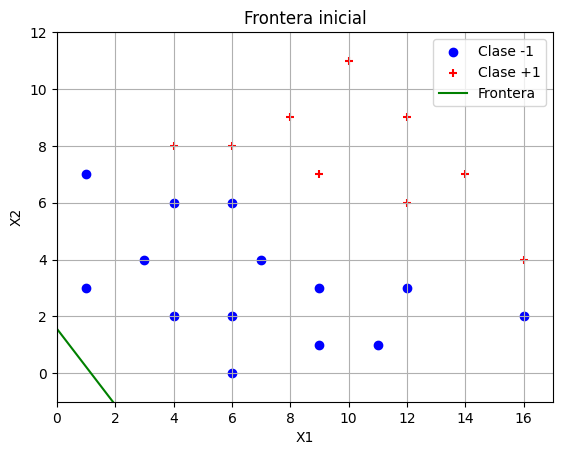

In [4]:
def perceptron_plot(X, y, w, title):
    x1_neg, x2_neg = [], []
    x1_pos, x2_pos = [], []

    for i in range(len(X)):
        if y[i] == -1:
            x1_neg.append(X[i][0])
            x2_neg.append(X[i][1])
        else:
            x1_pos.append(X[i][0])
            x2_pos.append(X[i][1])

    plt.scatter(x1_neg, x2_neg, color="blue", marker="o", label="Clase -1")
    plt.scatter(x1_pos, x2_pos, color="red", marker="+", label="Clase +1")

    if w[2] != 0:
        x1_vals = [0, 17]
        x2_vals = [
            -(w[0] + w[1] * 0) / w[2],
            -(w[0] + w[1] * 17) / w[2]
        ]
        plt.plot(x1_vals, x2_vals, color="green", label="Frontera")

    plt.title(title)
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.xlim(0, 17)
    plt.ylim(-1, 12)
    plt.legend()
    plt.grid(True)
    plt.show()

w_initial = initialize_weights()
perceptron_plot(X, y, w_initial, "Frontera inicial")

## Fase 4. Entrenamiento del Perceptrón
### Actividades 4.a, 4.b y 4.c
**Preguntas guía:**
* **4.a ¿Por qué poner un máximo de épocas?** Para evitar un bucle infinito si los datos no son linealmente separables.
* **4.b ¿Qué significa error igual a cero?** Que clasificó bien todos los puntos en esa época y ya convergió.
* **4.c ¿Por qué guardar copias de `w`?** Porque en Python las listas se pasan por referencia y se sobrescribirían todas con el peso final.

In [5]:
def perceptron_learning(X, y, w, lr, max_epochs):
    w_actual = [w[0], w[1], w[2]]
    epochs = 0
    updates = 0
    W_values = []
    E_values = []
    n = len(X)

    for epoch in range(max_epochs):
        epochs = epochs + 1
        errors = 0

        for i in range(n):
            y_pred = perceptron_compute(X[i], w_actual)
            if y_pred != y[i]:
                error = y[i] - y_pred
                w_actual[0] = w_actual[0] + lr * error
                w_actual[1] = w_actual[1] + lr * error * X[i][0]
                w_actual[2] = w_actual[2] + lr * error * X[i][1]
                errors = errors + 1
                updates = updates + 1

        E_values.append(errors / n)
        W_values.append([w_actual[0], w_actual[1], w_actual[2]])

        if errors == 0:
            break

    return w_actual, epochs, updates, W_values, E_values

## Fase 5. Entrenamiento con lr = 0.5
### Actividades 5.a y 5.b
**Preguntas guía:**
* **5.a ¿Logró converger?** Sí, porque el error final en `E_values` llegó a `0.0`.
* **5.b ¿Separa bien las clases respecto a la inicial?** Sí, separa todas las instancias correctamente, a diferencia de la recta aleatoria inicial.

Pesos iniciales: [0.3921795677048454, -0.41306116737058385, -0.07807818031472957]
Pesos finales: [-76.60782043229516, 3.5869388326294143, 8.92192181968527]
Épocas: 115
Actualizaciones: 427
Error final: 0.0


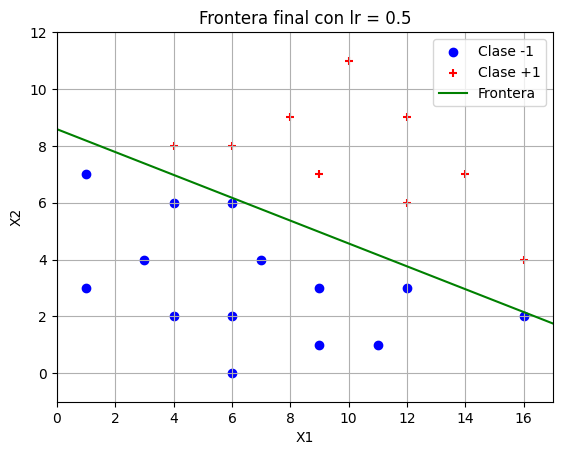

In [6]:
w = initialize_weights()
final_w, epochs, updates, W_values, E_values = perceptron_learning(
    X, y, w, lr=0.5, max_epochs=1000
)

print("Pesos iniciales:", w)
print("Pesos finales:", final_w)
print("Épocas:", epochs)
print("Actualizaciones:", updates)
print("Error final:", E_values[-1])

perceptron_plot(X, y, final_w, "Frontera final con lr = 0.5")

## Fase 6. Predicción con Nuevas Instancias
### Actividades 6.a y 6.b

| Instancia | Salida predicha |
| :---: | :---: |
| `[5, 5]` | `-1` |
| `[10, 6]` | `1` |
| `[6, 10]` | `1` |

**Preguntas guía:**
* **6.a ¿Son coherentes las predicciones?** Sí, `[5, 5]` queda abajo de la recta (`-1`) y los otros dos arriba (`1`).
* **6.b ¿Alguna predicción es discutible?** `[10, 6]` queda muy cerca de la frontera; si cambian los pesos iniciales, la recta podría moverse y cambiar su clase.

[5, 5] -> -1
[10, 6] -> 1
[6, 10] -> 1


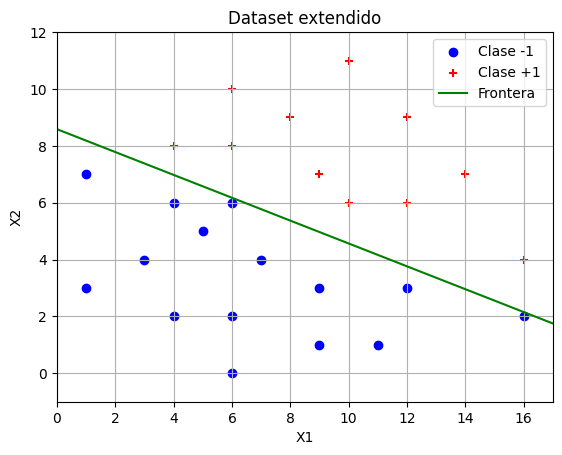

In [7]:
X_test = [
    [5, 5],
    [10, 6],
    [6, 10]
]

y_test = []
for punto in X_test:
    salida = perceptron_compute(punto, final_w)
    y_test.append(salida)
    print(punto, "->", salida)

X_ext = []
y_ext = []
for i in range(len(X)):
    X_ext.append(X[i])
    y_ext.append(y[i])
for i in range(len(X_test)):
    X_ext.append(X_test[i])
    y_ext.append(y_test[i])

perceptron_plot(X_ext, y_ext, final_w, "Dataset extendido")

## Fase 7. Evolución de la Frontera
### Actividades 7.a y 7.b
**Preguntas guía:**
* **7.a ¿El cambio es estable o brusco?** Brusco al inicio cuando hay muchos errores y más estable al final.
* **7.b ¿Qué influye en la inclinación y qué hace el bias?** $w_1$ y $w_2$ definen la inclinación de la recta; $w_0$ (bias) la desplaza arriba o abajo.

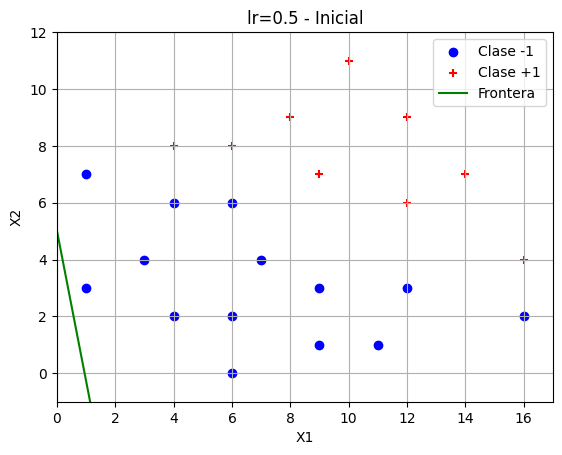

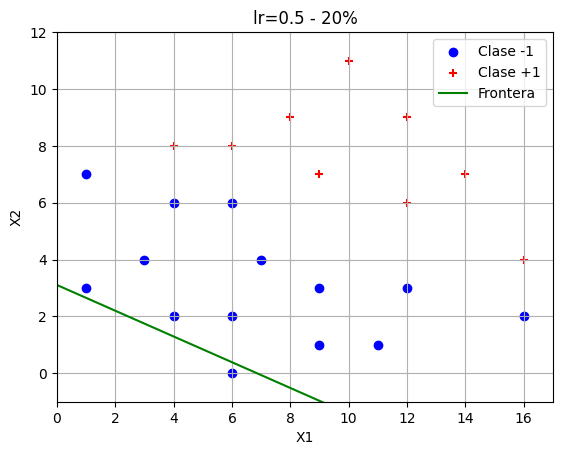

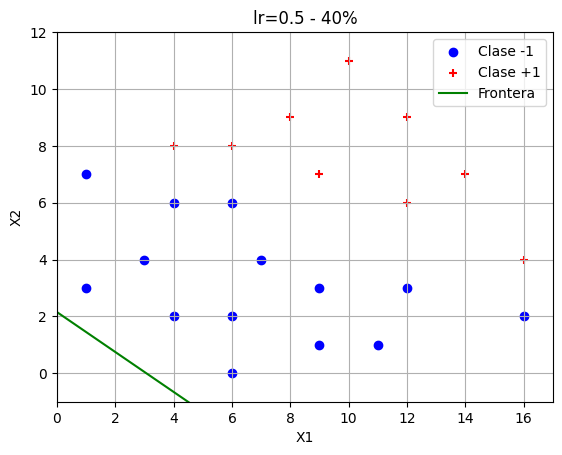

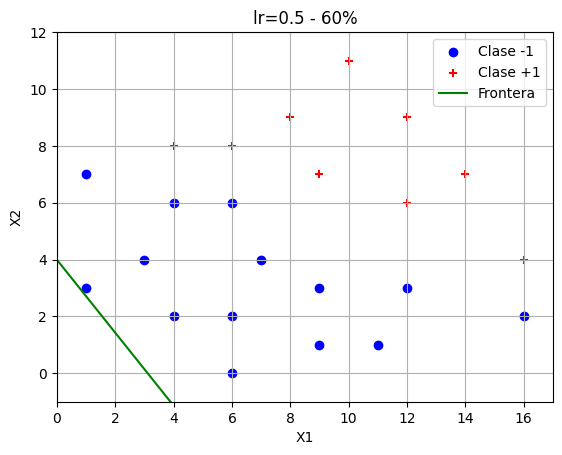

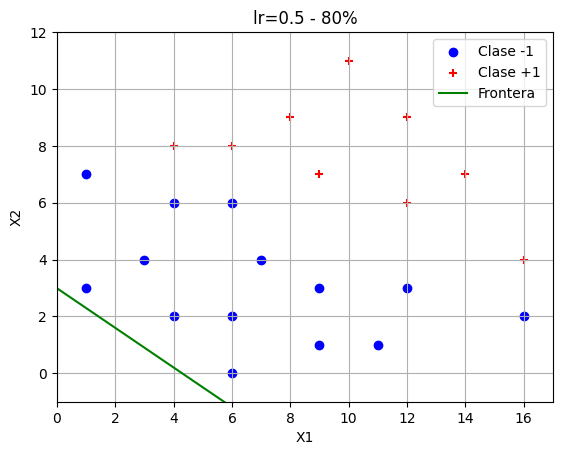

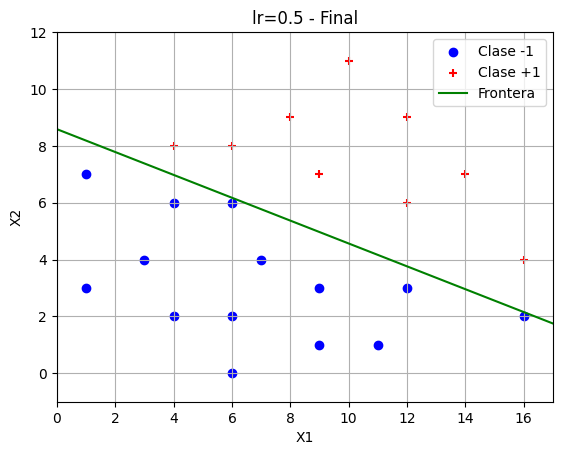

In [8]:
def graficar_evolucion(X, y, w_ini, W_values, nombre):
    estados = [w_ini] + W_values
    total = len(estados)

    if total <= 6:
        for i in range(total):
            perceptron_plot(X, y, estados[i], nombre + " - Estado " + str(i))
    else:
        porcentajes = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
        nombres = ["Inicial", "20%", "40%", "60%", "80%", "Final"]
        for i in range(6):
            idx = int(porcentajes[i] * (total - 1))
            perceptron_plot(X, y, estados[idx], nombre + " - " + nombres[i])

graficar_evolucion(X, y, w, W_values, "lr=0.5")

## Fase 8. Evolución del Error
### Actividades 8.a y 8.b
**Preguntas guía:**
* **8.a ¿El error baja siempre continuo?** No, a veces sube porque al corregir un punto se puede desajustar otro temporalmente.
* **8.b ¿Error cero significa perfección futura?** No, solo significa que separó bien los datos de entrenamiento, pero no garantiza el mejor margen para datos nuevos.

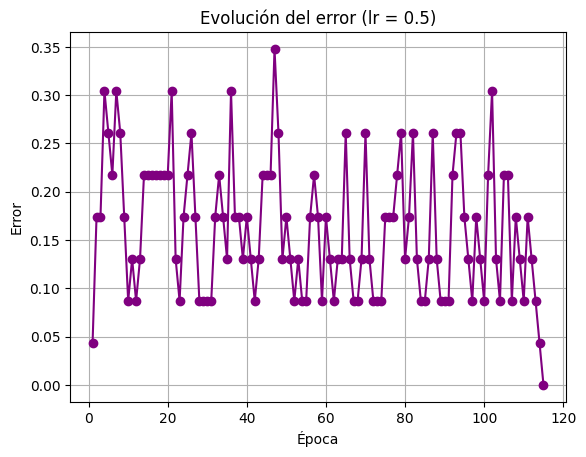

In [9]:
def plot_error(E_values, title):
    epocas = []
    for i in range(1, len(E_values) + 1):
        epocas.append(i)

    plt.plot(epocas, E_values, marker="o", color="purple")
    plt.title(title)
    plt.xlabel("Época")
    plt.ylabel("Error")
    plt.grid(True)
    plt.show()

plot_error(E_values, "Evolución del error (lr = 0.5)")

## Fase 9. Comparación de Tasas de Aprendizaje
### Actividades 9.a, 9.b y 9.c

| lr | Épocas | Actualizaciones | Error final | Pesos finales |
| :---: | :---: | :---: | :---: | :---: |
| `0.3` | `74` | `257` | `0.0` | `[-31.0702, 0.9186, 4.2054]` |
| `0.5` | `264` | `897` | `0.0` | `[-133.4702, 5.7186, 16.0054]` |
| `0.8` | `284` | `920` | `0.0` | `[-214.8702, 9.3186, 25.6054]` |

**Preguntas guía:**
* **9.a ¿Por qué usar los mismos pesos iniciales?** Para que todos partan desde el mismo punto y comparar solo el efecto de `lr`.
* **9.b ¿Cuál convergió en menos épocas y si siempre es la mejor?** `lr = 0.3` (74 épocas), pero no siempre es la mejor porque tasas muy bajas avanzan lento y tasas muy altas oscilan más.
* **9.c ¿Por qué pesos diferentes clasifican bien?** Porque existen infinitas rectas posibles dentro del espacio libre que separa ambas clases.

---

## Conclusiones
1. Se implementó el perceptrón manualmente con Python básico, logrando separar las dos clases linealmente separables sin librerías de machine learning.
2. Distintas tasas de aprendizaje generan distintos vectores de pesos finales, demostrando que la frontera de decisión no es única.

Pesos iniciales: [-0.47020278056192966, -0.28136202519639664, 0.005355288103362388]


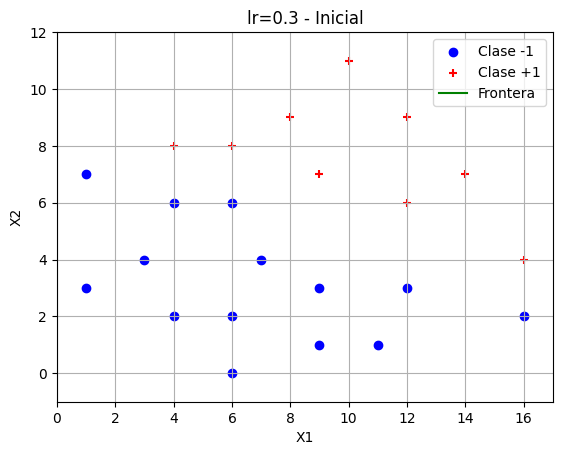

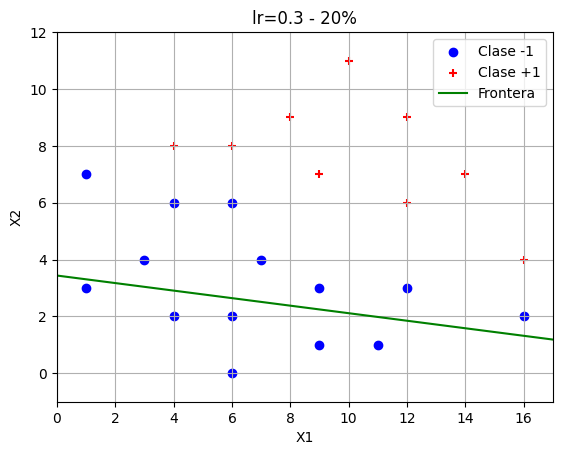

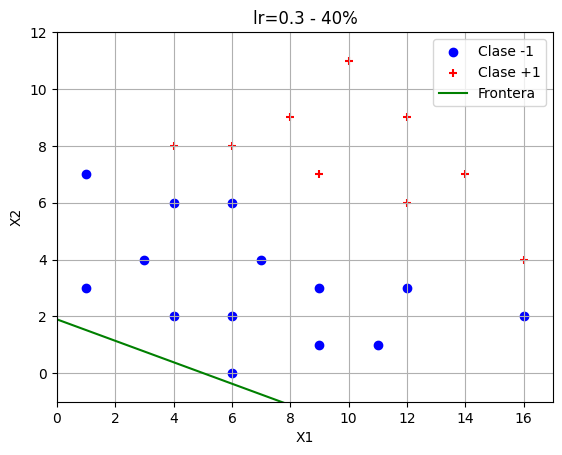

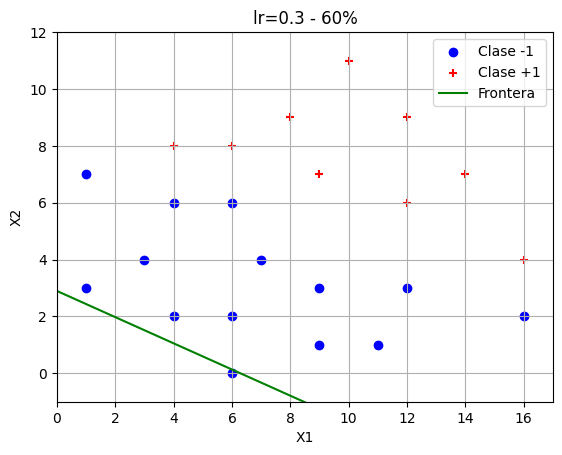

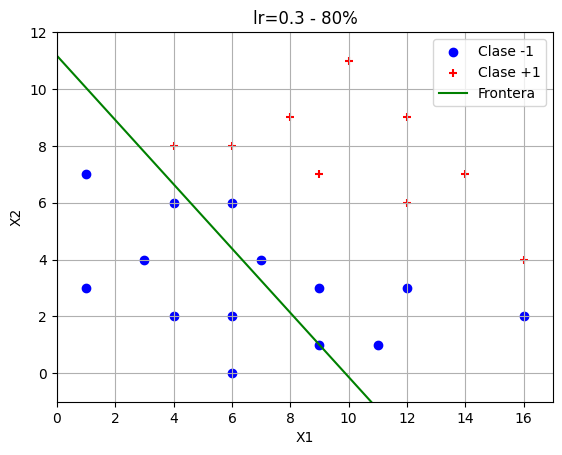

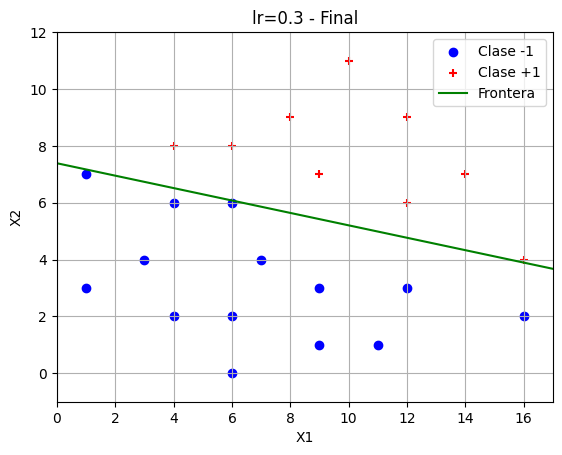

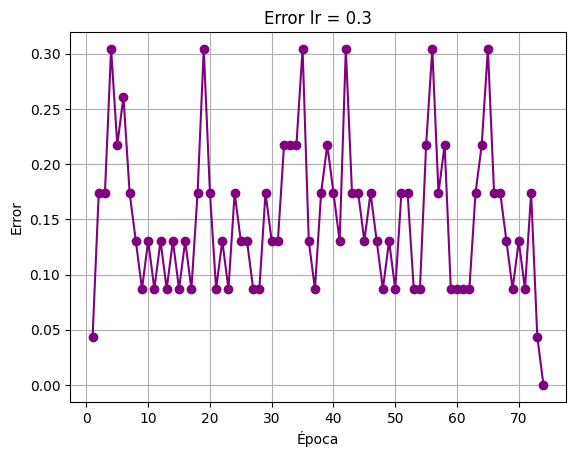

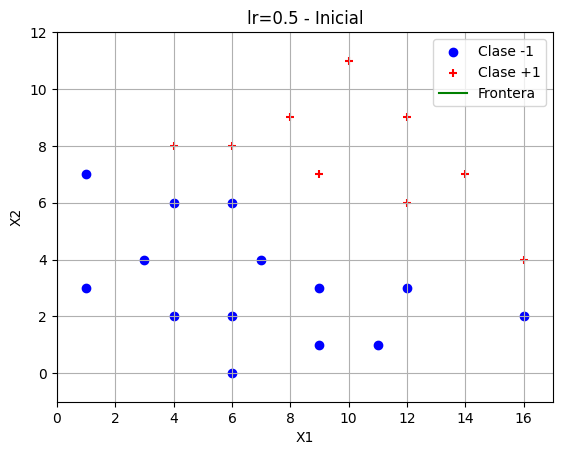

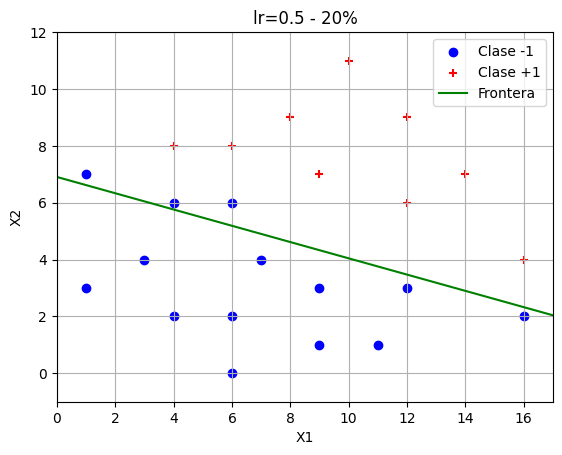

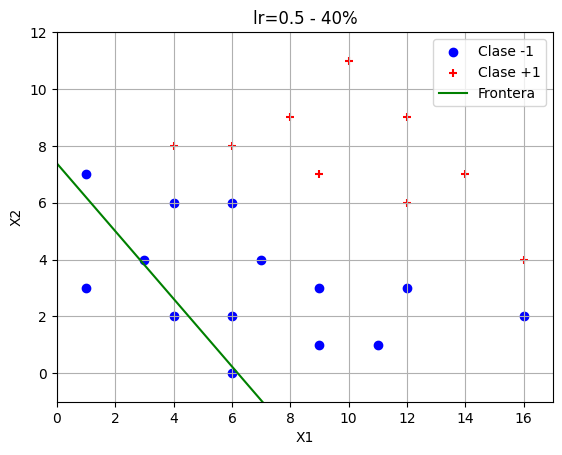

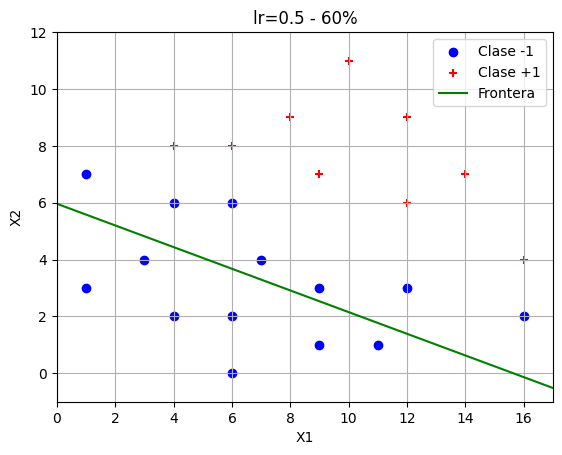

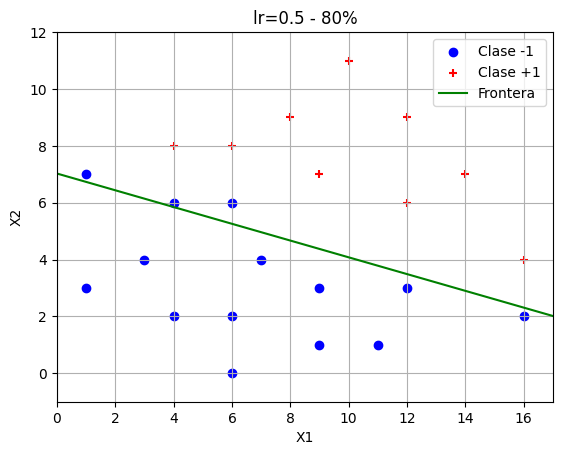

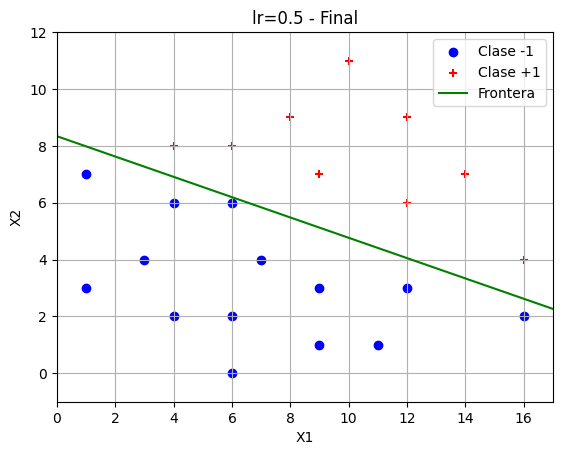

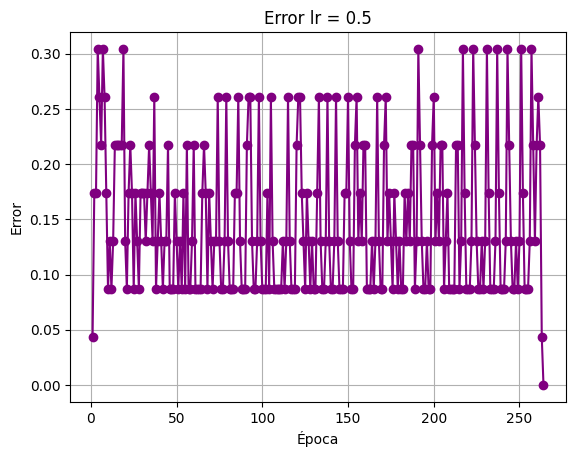

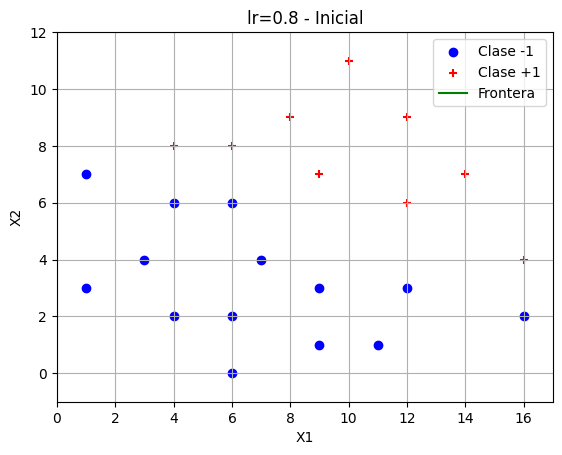

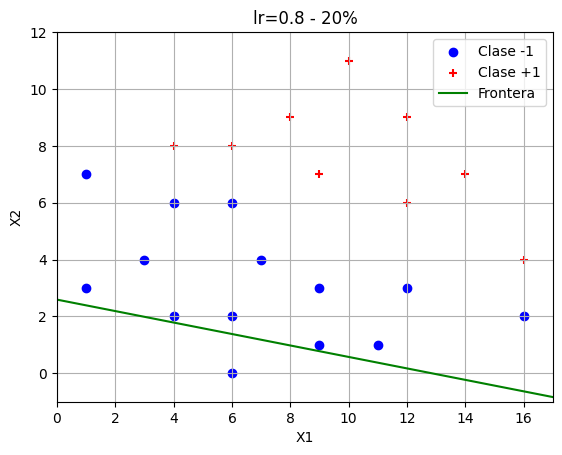

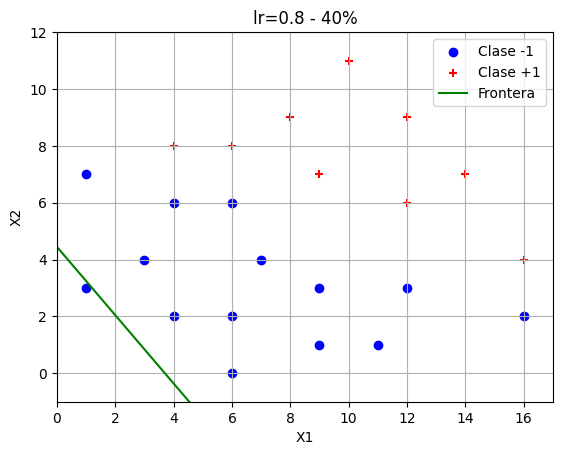

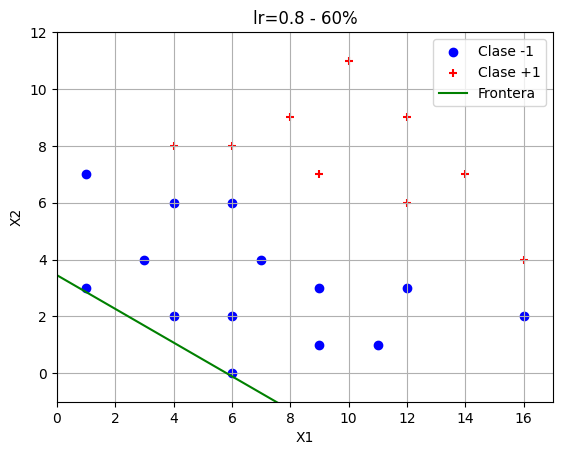

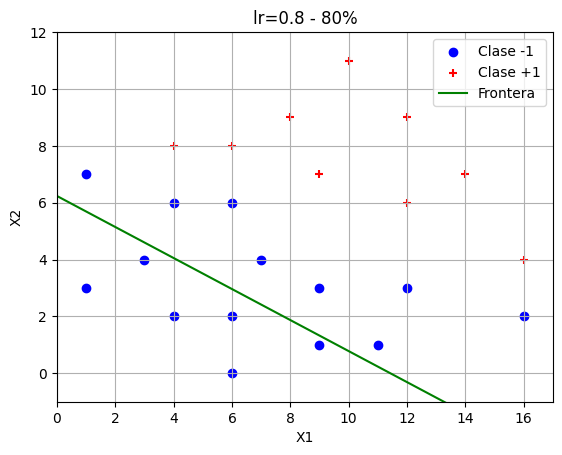

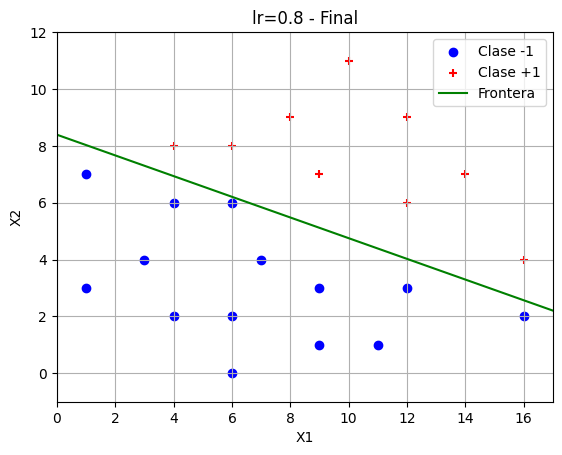

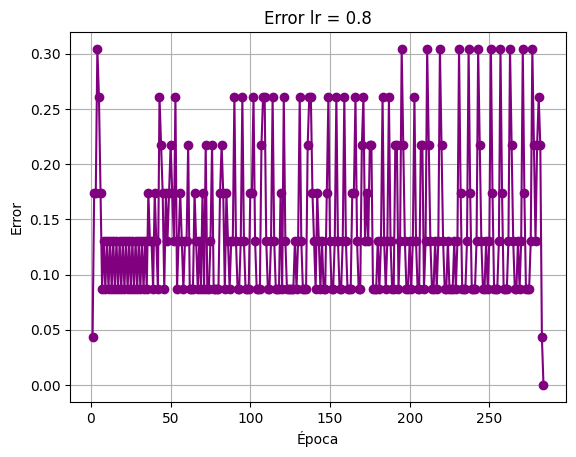

lr  | Épocas | Actualizaciones | Error | Pesos finales
0.3 | 74    | 257             | 0.0  | [-31.0702, 0.9186, 4.2054]
0.5 | 264    | 897             | 0.0  | [-133.4702, 5.7186, 16.0054]
0.8 | 284    | 920             | 0.0  | [-214.8702, 9.3186, 25.6054]


In [10]:
w_base = initialize_weights()
print("Pesos iniciales:", w_base)

tasas = [0.3, 0.5, 0.8]
tabla = []

for lr in tasas:
    w_copia = [w_base[0], w_base[1], w_base[2]]
    w_fin, ep, upd, W_hist, E_hist = perceptron_learning(X, y, w_copia, lr, 1000)
    tabla.append([lr, ep, upd, E_hist[-1], w_fin])

    graficar_evolucion(X, y, w_base, W_hist, "lr=" + str(lr))
    plot_error(E_hist, "Error lr = " + str(lr))

print("lr  | Épocas | Actualizaciones | Error | Pesos finales")
for fila in tabla:
    pesos_red = [round(fila[4][0], 4), round(fila[4][1], 4), round(fila[4][2], 4)]
    print(fila[0], "|", fila[1], "   |", fila[2], "            |", fila[3], " |", pesos_red)